In [26]:
import imageio
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from torch import optim
import os
import torchvision.utils as vutils
import numpy as np
from torchvision import datasets
from torchvision import transforms
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch
from torchvision.datasets import ImageFolder as ImageFolder

In [10]:
!wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --savecookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate'https://docs.google.com/uc?export=download&id=1KIgyF4vpFDeaItq6Nz22vrWyouLCz87' -O- | sed -rn 's/.*confirm=([0-9A-Zaz_]+).*/\1\n/p')&id=1KIgyF4vpFDea-Itq6Nz22vrWyouLCz87" -O anime-facesdataset.zip && rm -rf /tmp/cookies.txt

wget: unrecognized option '--savecookies'
wget: unrecognized option '--no-check-certificatehttps://docs.google.com/uc?export=download&id=1KIgyF4vpFDeaItq6Nz22vrWyouLCz87'
Usage: wget [OPTION]... [URL]...

Try `wget --help' for more options.
Cannot open cookies file ‘/tmp/cookies.txt’: No such file or directory
--2023-12-05 23:06:58--  https://docs.google.com/uc?export=download&confirm=&id=1KIgyF4vpFDea-Itq6Nz22vrWyouLCz87
Resolving docs.google.com (docs.google.com)... 74.125.204.102, 74.125.204.138, 74.125.204.139, ...
Connecting to docs.google.com (docs.google.com)|74.125.204.102|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://doc-0k-54-docs.googleusercontent.com/docs/securesc/ha0ro937gcuc7l7deffksulhg5h7mbp1/i1f4gv62ppbb00g840stnpqqc8dmiekd/1701817575000/11989816279260235431/*/1KIgyF4vpFDea-Itq6Nz22vrWyouLCz87?e=download&uuid=a03df786-5ab7-49a0-bdb5-2d47228c3a61 [following]
--2023-12-05 23:06:59--  https://doc-0k-54-docs.googleusercontent.co

In [13]:
!unzip anime-facesdataset.zip -d dataset

Streaming output truncated to the last 5000 lines.
  inflating: dataset/images/62764_2019.jpg  
  inflating: dataset/images/62765_2019.jpg  
  inflating: dataset/images/62766_2019.jpg  
  inflating: dataset/images/62767_2019.jpg  
  inflating: dataset/images/62768_2019.jpg  
  inflating: dataset/images/62769_2019.jpg  
  inflating: dataset/images/6276_2003.jpg  
  inflating: dataset/images/62770_2019.jpg  
  inflating: dataset/images/62771_2019.jpg  
  inflating: dataset/images/62772_2019.jpg  
  inflating: dataset/images/62773_2019.jpg  
  inflating: dataset/images/62774_2019.jpg  
  inflating: dataset/images/62775_2019.jpg  
  inflating: dataset/images/62776_2019.jpg  
  inflating: dataset/images/62777_2019.jpg  
  inflating: dataset/images/62778_2019.jpg  
  inflating: dataset/images/62779_2019.jpg  
  inflating: dataset/images/6277_2003.jpg  
  inflating: dataset/images/62780_2019.jpg  
  inflating: dataset/images/62781_2019.jpg  
  inflating: dataset/images/62782_2019.jpg  
  infl

In [28]:
dataroot = "./dataset/" # Root directory for dataset

data_transform = transforms.Compose([
    transforms.Resize([28, 28]),
    transforms.ToTensor(),
    transforms.Normalize(mean=[.5], std=[.5]),
    transforms.Grayscale()
])
dataset = ImageFolder(root=dataroot,transform=data_transform)

In [30]:
data_loader = torch.utils.data.DataLoader(dataset = dataset,
                                        batch_size=64,
                                        shuffle=True,
                                        num_workers=4,
                                        drop_last=True)

/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


In [31]:
def show_samples(data_loader):
  images, labels = next(iter(data_loader))
  plt.figure(figsize=(8,8))

  for i in range(64):
    ax = plt.subplot(8, 8, i + 1)
    image = torch.squeeze(images[i])
    class_label = int(labels[i])
    plt.imshow(image, cmap='gray')
    plt.axis('off')

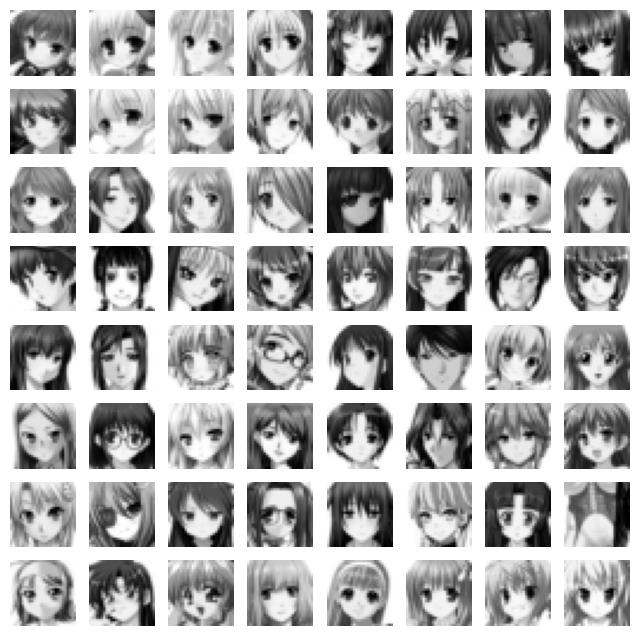

In [32]:
show_samples(data_loader)